# LightGBM Model Building & Out-of-Time Historical Regime Validation (2007–2015)
**Master's Dissertation: Time-Series Forecasting of Brent Crude Oil Prices**

## Overview & Methodology (Approach A)
This notebook implements **Approach A: Out-of-Time Historical Regime Testing**:
1. **Modern Era Training (2016–2026)**: Feature engineering and `TimeSeriesSplit` 5-fold cross-validation hyperparameter tuning for **LightGBM** and **XGBoost** on modern market data.
2. **Out-of-Time Historical Regime Testing (2007–2015)**: Testing modern-trained models on an earlier historical decade containing major black-swan market shocks:
   - **2008 Financial Crisis**: Brent spiked to $147/bbl then collapsed to $35/bbl.
   - **2014 OPEC Price War**: Brent crashed from $115/bbl down to $27/bbl.
3. **Side-by-Side Visualisation**: Trajectory comparison, performance metrics bar charts, feature importances, and residual distributions.

In [2]:
import sys, os
sys.path.append('../src')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from data_loader import build_master_dataset, engineer_features
from models_engine import train_and_evaluate_all, validate_on_secondary_dataset

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'

### 1. Data Ingestion: Modern Era (2016–2026) vs Historical Regime Era (2007–2015)

In [3]:
# Modern Era (2016-2026)
df_modern = build_master_dataset(start_date='2016-01-01')
df_modern_eng = engineer_features(df_modern, target_col='Brent_Crude')

# Historical Crisis Era (2007-2015)
df_hist = build_master_dataset(start_date='2007-07-30', end_date='2016-01-01')
df_hist_eng = engineer_features(df_hist, target_col='Brent_Crude')

print('Modern Dataset Shape (2016-2026):', df_modern_eng.shape)
print('Historical Dataset Shape (2007-2015):', df_hist_eng.shape)

Modern Dataset Shape (2016-2026): (549, 16)
Historical Dataset Shape (2007-2015): (437, 16)


### 2. Model Training & TimeSeriesSplit Cross-Validation Tuning (Modern Era)

In [4]:
modern_results = train_and_evaluate_all(df_modern_eng, tune_models=True)
metrics_df = modern_results['metrics']

print('--- Primary Modern Era Model Benchmark Table (2016-2026) ---')
display(metrics_df)

--- Primary Modern Era Model Benchmark Table (2016-2026) ---


,Model,Composite Score,MAE ($),RMSE ($),R2 Score,MAPE (%),Dir Accuracy (%),Durbin-Watson,Hyperparameters
0,SARIMAX (Baseline),20.92,14.55,15.98,-0.6357,20.27,52.3,0.09,"order=(1,1,1)"
1,LASSO Regression,60.30,3.28,5.16,0.8292,4.00,52.3,1.17,alpha=0.01
2,Random Forest,57.18,3.58,5.20,0.8267,4.52,45.0,1.43,"n_est=100, max_depth=4"
3,XGBoost,60.38,3.41,5.07,0.8350,4.29,51.4,1.36,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
4,LightGBM,58.53,3.40,4.85,0.8491,4.32,44.0,1.37,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est..."
5,LSTM (Deep Learning),46.24,4.93,7.73,0.6172,5.95,52.3,0.49,"Units=64, Epochs=50"


### 3. Out-of-Time Historical Regime Testing (2007–2015)

In [5]:
val_results = validate_on_secondary_dataset(df_modern_eng, df_hist_eng, modern_results['models'])
comp_df = val_results['comparison_metrics']

print('--- Cross-Era Performance Indicators Comparison ---')
display(comp_df)

--- Cross-Era Performance Indicators Comparison ---


,Model,Composite Score,MAE ($),RMSE ($),R2 Score,MAPE (%),Dir Accuracy (%),Durbin-Watson,Hyperparameters
0,XGBoost (Modern Era 2016-2026),60.38,3.41,5.07,0.8350,4.29,51.4,1.36,
1,LightGBM (Modern Era 2016-2026),58.53,3.40,4.85,0.8491,4.32,44.0,1.37,
2,XGBoost (Historical Regime 2007-2015),56.42,4.38,6.59,0.9281,4.70,45.9,0.50,
3,LightGBM (Historical Regime 2007-2015),52.06,4.41,6.75,0.9244,4.81,36.5,0.45,


### 4. Visualisation 1: Trajectory Comparison (Modern 2016–2026 vs Historical 2007–2015)

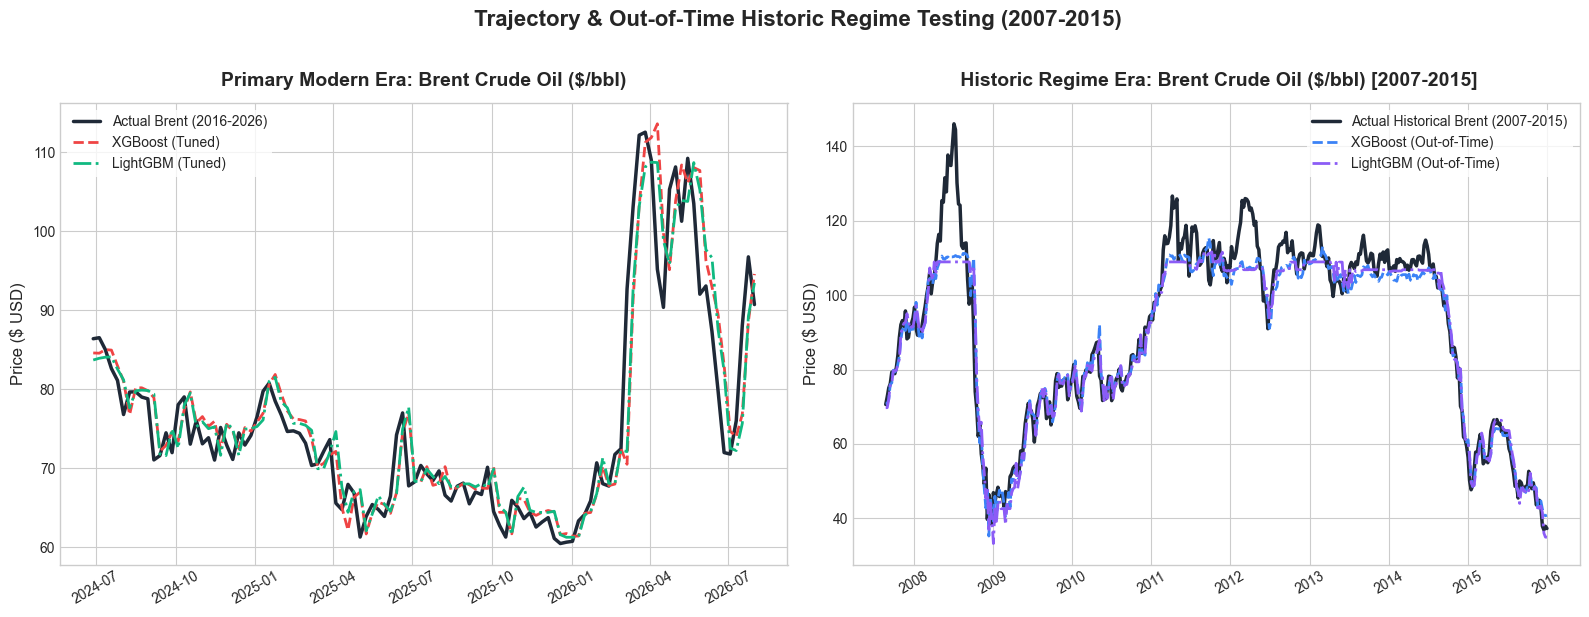

In [7]:
# Trajectory Comparison: Modern Era vs Historical Regime Era
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

brent_idx = val_results['brent_index']
axes[0].plot(brent_idx, val_results['brent_actual'], label='Actual Brent (2016-2026)', color='#1f2937', linewidth=2.5)
axes[0].plot(brent_idx, val_results['brent_xgb_preds'], label='XGBoost (Tuned)', color='#ef4444', linestyle='--', linewidth=2)
axes[0].plot(brent_idx, val_results['brent_lgb_preds'], label='LightGBM (Tuned)', color='#10b981', linestyle='-.', linewidth=2)
axes[0].set_title('Primary Modern Era: Brent Crude Oil ($/bbl)', fontsize=14, fontweight='bold', pad=12)
axes[0].set_ylabel('Price ($ USD)', fontsize=12)
axes[0].legend(frameon=True, facecolor='white', edgecolor='none')
axes[0].tick_params(axis='x', rotation=30)

wti_idx = val_results['wti_index']
axes[1].plot(wti_idx, val_results['wti_actual'], label='Actual Historical Brent (2007-2015)', color='#1f2937', linewidth=2.5)
axes[1].plot(wti_idx, val_results['wti_xgb_preds'], label='XGBoost (Out-of-Time)', color='#3b82f6', linestyle='--', linewidth=2)
axes[1].plot(wti_idx, val_results['wti_lgb_preds'], label='LightGBM (Out-of-Time)', color='#8b5cf6', linestyle='-.', linewidth=2)
axes[1].set_title(' Historic Regime Era: Brent Crude Oil ($/bbl) [2007-2015]', fontsize=14, fontweight='bold', pad=12)
axes[1].set_ylabel('Price ($ USD)', fontsize=12)
axes[1].legend(frameon=True, facecolor='white', edgecolor='none')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle(' Trajectory & Out-of-Time Historic Regime Testing (2007-2015)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5. Visualisation 2: Performance Indicators Side-by-Side Bar Charts

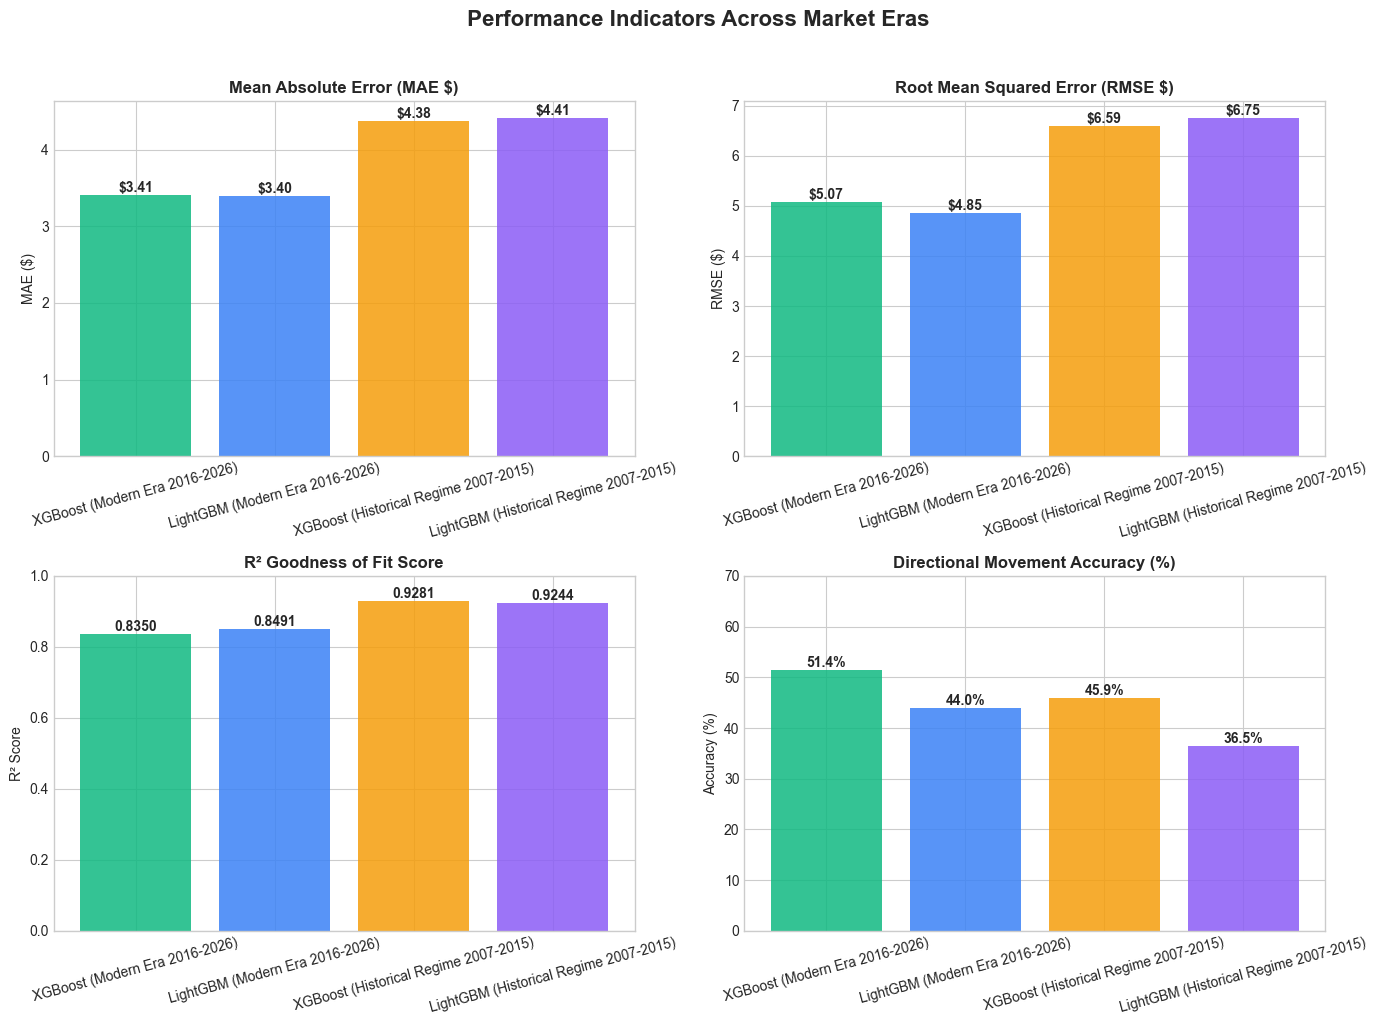

In [12]:
# Performance Bar Charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
models = comp_df['Model'].values
colors = ['#10b981', '#3b82f6', '#f59e0b', '#8b5cf6']

bars1 = axes[0, 0].bar(models, comp_df['MAE ($)'], color=colors, alpha=0.85)
axes[0, 0].set_title('Mean Absolute Error (MAE $)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('MAE ($)', fontsize=10)
axes[0, 0].tick_params(axis='x', rotation=15)
for bar in bars1:
    axes[0, 0].annotate(f'${bar.get_height():.2f}', (bar.get_x() + bar.get_width()/2, bar.get_height()), ha='center', va='bottom', fontsize=10, fontweight='bold')

bars2 = axes[0, 1].bar(models, comp_df['RMSE ($)'], color=colors, alpha=0.85)
axes[0, 1].set_title('Root Mean Squared Error (RMSE $)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('RMSE ($)', fontsize=10)
axes[0, 1].tick_params(axis='x', rotation=15)
for bar in bars2:
    axes[0, 1].annotate(f'${bar.get_height():.2f}', (bar.get_x() + bar.get_width()/2, bar.get_height()), ha='center', va='bottom', fontsize=10, fontweight='bold')

bars3 = axes[1, 0].bar(models, comp_df['R2 Score'], color=colors, alpha=0.85)
axes[1, 0].set_title('R² Goodness of Fit Score', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('R² Score', fontsize=10)
axes[1, 0].set_ylim(0, 1.0)
axes[1, 0].tick_params(axis='x', rotation=15)
for bar in bars3:
    axes[1, 0].annotate(f'{bar.get_height():.4f}', (bar.get_x() + bar.get_width()/2, bar.get_height()), ha='center', va='bottom', fontsize=10, fontweight='bold')

bars4 = axes[1, 1].bar(models, comp_df['Dir Accuracy (%)'], color=colors, alpha=0.85)
axes[1, 1].set_title('Directional Movement Accuracy (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Accuracy (%)', fontsize=10)
axes[1, 1].set_ylim(0, 70)
axes[1, 1].tick_params(axis='x', rotation=15)
for bar in bars4:
    axes[1, 1].annotate(f'{bar.get_height():.1f}%', (bar.get_x() + bar.get_width()/2, bar.get_height()), ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle(' Performance Indicators Across Market Eras', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 6. Visualisation 3: Feature Importance Comparison (XGBoost vs LightGBM)

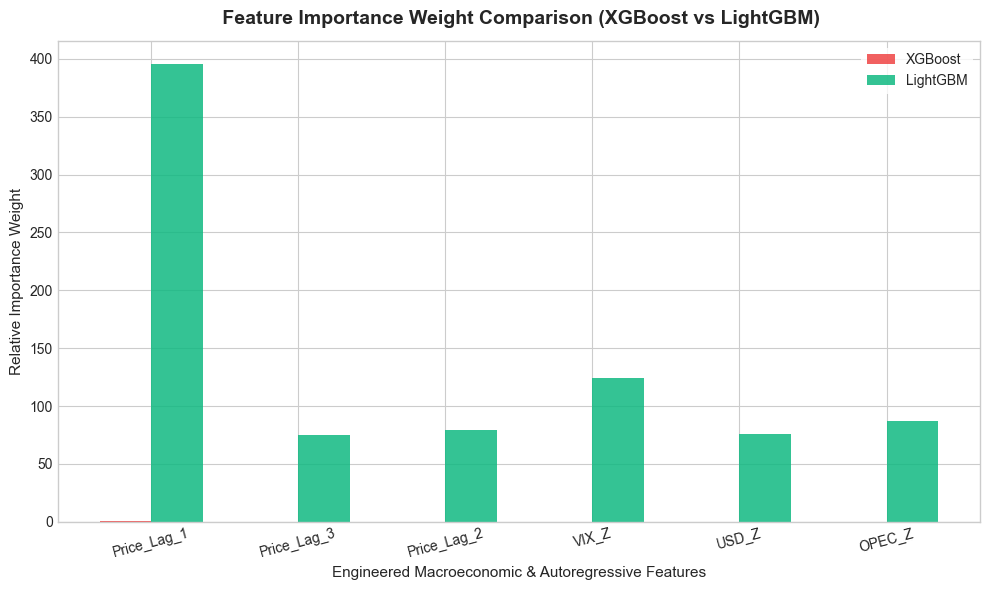

In [11]:
fi_df = modern_results['feature_importances']
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(fi_df))
width = 0.35
ax.bar(x - width/2, fi_df['XGBoost'], width, label='XGBoost', color='#ef4444', alpha=0.85)
ax.bar(x + width/2, fi_df['LightGBM'], width, label='LightGBM', color='#10b981', alpha=0.85)

ax.set_title(' Feature Importance Weight Comparison (XGBoost vs LightGBM)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Engineered Macroeconomic & Autoregressive Features', fontsize=11)
ax.set_ylabel('Relative Importance Weight', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(fi_df['Feature'], fontsize=10, rotation=15)
ax.legend(frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()

### 7. Visualisation 4: Residual Density Distribution Plots

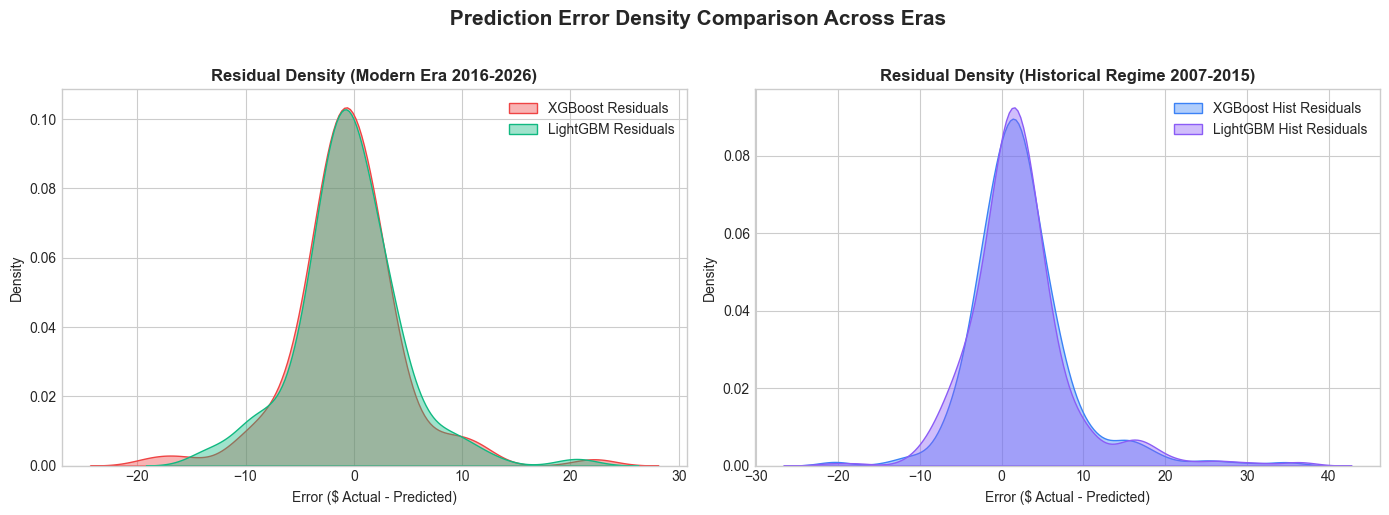

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

res_xgb = val_results['brent_actual'] - val_results['brent_xgb_preds']
res_lgb = val_results['brent_actual'] - val_results['brent_lgb_preds']
sns.kdeplot(res_xgb, ax=axes[0], fill=True, color='#ef4444', label='XGBoost Residuals', alpha=0.4)
sns.kdeplot(res_lgb, ax=axes[0], fill=True, color='#10b981', label='LightGBM Residuals', alpha=0.4)
axes[0].set_title('Residual Density (Modern Era 2016-2026)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Error ($ Actual - Predicted)', fontsize=10)
axes[0].legend()

hist_res_xgb = val_results['wti_actual'] - val_results['wti_xgb_preds']
hist_res_lgb = val_results['wti_actual'] - val_results['wti_lgb_preds']
sns.kdeplot(hist_res_xgb, ax=axes[1], fill=True, color='#3b82f6', label='XGBoost Hist Residuals', alpha=0.4)
sns.kdeplot(hist_res_lgb, ax=axes[1], fill=True, color='#8b5cf6', label='LightGBM Hist Residuals', alpha=0.4)
axes[1].set_title('Residual Density (Historical Regime 2007-2015)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Error ($ Actual - Predicted)', fontsize=10)
axes[1].legend()

plt.suptitle(' Prediction Error Density Comparison Across Eras', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()